In [7]:
import pandas as pd

df = pd.read_csv("../data/raw/superstore_sales.csv",encoding="latin-1")

print(df.shape)
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df.head()


(7769, 20)
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode        15
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64
Duplicates: 30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,Telangana,South,OFF-AR-10061,Office Supplies,Art,Drawing Sketch Pad,976.0,2,0.20,62.04
1,2,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,Telangana,South,OFF-LA-10072,Office Supplies,Labels,Removable Labels,1064.0,7,0.20,260.12
2,3,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,Telangana,South,FUR-FU-10028,Furniture,Furnishings,Framed Wall Art,1760.0,4,0.20,28.54
3,4,IN-2021-100001,2021-01-01,2021-01-04,First Class,NB-10847,Nisha Bose,Corporate,India,Kanpur,Uttar Pradesh,North,FUR-FU-10030,Furniture,Furnishings,Floor Mat Anti-Slip,11447.5,5,0.05,1875.44
4,5,IN-2021-100001,2021-01-01,2021-01-04,First Class,NB-10847,Nisha Bose,Corporate,India,Kanpur,Uttar Pradesh,North,FUR-FU-10026,Furniture,Furnishings,Wall Clock,3276.0,7,0.40,-1170.22


In [8]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[ \-\.]", "_", regex=True))


In [9]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

In [10]:
df = df.drop_duplicates()


In [11]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["profit_margin_pct"] = (df["profit"] / df["sales"] * 100).round(2)
df["delivery_days"] = (df["ship_date"] - df["order_date"]).dt.days

In [12]:
df.to_csv("../data/cleaned/superstore_clean.csv", index=False)
df.head()


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,sub_category,product_name,sales,quantity,discount,profit,year,month,profit_margin_pct,delivery_days
0,1,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,...,Art,Drawing Sketch Pad,976.0,2,0.20,62.04,2021,2021-01,6.36,1
1,2,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,...,Labels,Removable Labels,1064.0,7,0.20,260.12,2021,2021-01,24.45,1
2,3,IN-2021-100000,2021-01-01,2021-01-02,First Class,RV-11498,Rahul Verma,Corporate,India,Hyderabad,...,Furnishings,Framed Wall Art,1760.0,4,0.20,28.54,2021,2021-01,1.62,1
3,4,IN-2021-100001,2021-01-01,2021-01-04,First Class,NB-10847,Nisha Bose,Corporate,India,Kanpur,...,Furnishings,Floor Mat Anti-Slip,11447.5,5,0.05,1875.44,2021,2021-01,16.38,3
4,5,IN-2021-100001,2021-01-01,2021-01-04,First Class,NB-10847,Nisha Bose,Corporate,India,Kanpur,...,Furnishings,Wall Clock,3276.0,7,0.40,-1170.22,2021,2021-01,-35.72,3


In [15]:
df.columns

Index(['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode',
       'customer_id', 'customer_name', 'segment', 'country', 'city', 'state',
       'region', 'product_id', 'category', 'sub_category', 'product_name',
       'sales', 'quantity', 'discount', 'profit', 'year', 'month',
       'profit_margin_pct', 'delivery_days'],
      dtype='object')

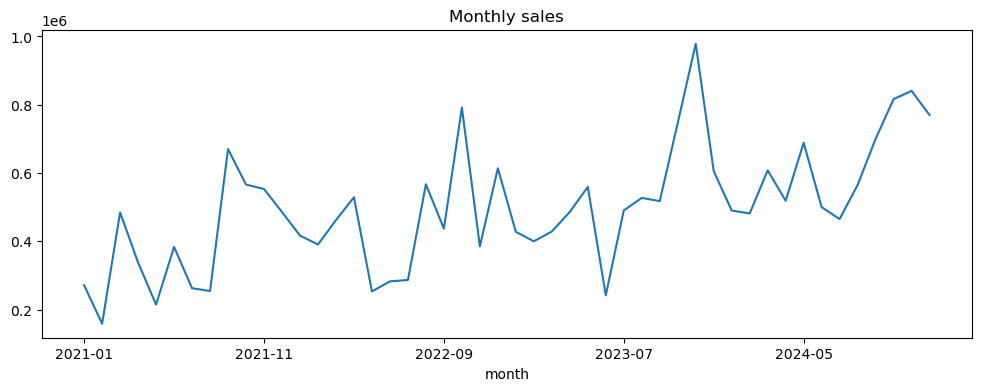

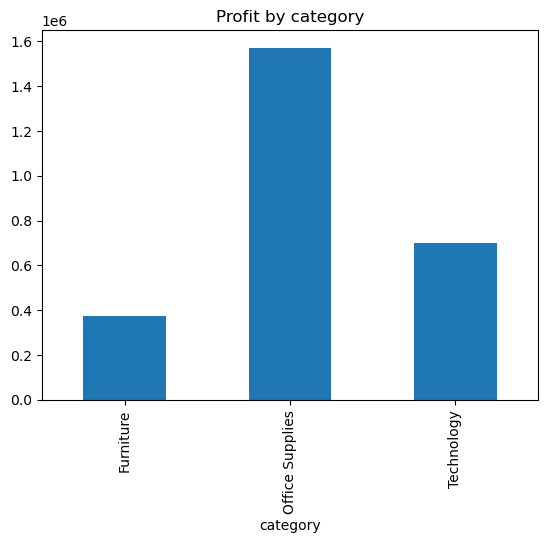

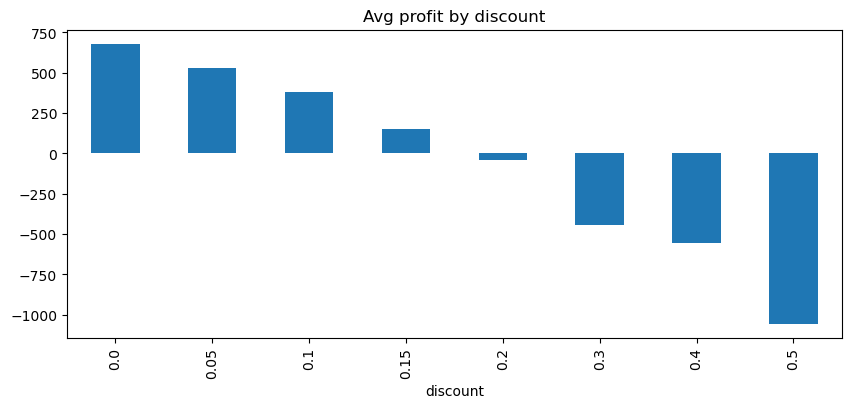

In [16]:
import matplotlib.pyplot as plt

df.groupby("month")["sales"].sum().plot(figsize=(12,4), title="Monthly sales")
plt.show()

df.groupby("category")["profit"].sum().plot(kind="bar", title="Profit by category")
plt.show()

df.groupby("discount")["profit"].mean().plot(kind="bar", figsize=(10,4), title="Avg profit by discount")
plt.show()

In [22]:
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

password = getpass("PostgreSQL password: ")

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,          
    host="localhost",
    port=5432,
    database="superstore_db",
))

df.to_sql("orders", engine, if_exists="replace", index=False)

PostgreSQL password:  ········


739

In [20]:
%pip install psycopg2-binary sqlalchemy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 1.2 MB/s eta 0:00:02
   ----------- ---------------------------- 0.8/2.8 MB 1.2 MB/s eta 0:00:02
   --------------- ------------------------ 1.0/2.8 MB 1.2 MB/s eta 0:00:02
   ------------------ --------------------- 1.3/2.8 MB 1.2 MB/s eta 0:00:02
   ---------------------- ----------------- 1.6/2.8 MB 1.1 MB/s eta 0:00:02
   -------------------------- ------------- 1.8/2.8 MB 1.1 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.8 MB 1.1 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.8 MB 1.1 MB/s eta 0:00:01
   ---------------------------------- ----- 2.4/2.8 MB 1.1 MB/s eta 0:00:01
   ----------------------------

In [23]:

q1 = """
SELECT region, category, ROUND(SUM(profit)::numeric, 2) AS total_profit
FROM orders
GROUP BY region, category
ORDER BY total_profit;
"""
pd.read_sql(q1, engine)

,region,category,total_profit
0,Central,Furniture,-43464.14
1,Central,Technology,-41113.01
2,East,Furniture,29833.95
3,East,Technology,69125.67
4,West,Furniture,90646.89
5,Central,Office Supplies,122521.27
6,North,Furniture,142304.86
7,South,Furniture,155956.23
8,North,Technology,196739.89
9,West,Technology,228171.69


In [26]:
q2 = """
SELECT month,
       ROUND(SUM(sales)::numeric, 2)  AS sales,
       ROUND(SUM(profit)::numeric, 2) AS profit
FROM orders
GROUP BY month
ORDER BY month;
"""

q3 = """
SELECT customer_name,
       ROUND(SUM(sales)::numeric, 2)  AS sales,
       ROUND(SUM(profit)::numeric, 2) AS profit
FROM orders
GROUP BY customer_name
ORDER BY SUM(sales) DESC
LIMIT 10;
"""

from sqlalchemy import text

q4 = """
SELECT CASE WHEN discount = 0 THEN 'No discount'
            WHEN discount <= 0.2 THEN 'Up to 20%'
            ELSE 'Above 20%' END AS discount_band,
       ROUND(SUM(profit)::numeric, 2) AS total_profit,
       COUNT(*) AS orders
FROM orders
GROUP BY 1
ORDER BY 1;
"""

pd.read_sql(text(q4), engine)

,discount_band,total_profit,orders
0,Above 20%,-560319.61,900
1,No discount,2364833.12,3478
2,Up to 20%,841377.88,3361


In [29]:
from sqlalchemy import text

for q in (q1, q2, q3, q4):
    display(pd.read_sql(text(q), engine))

,region,category,total_profit
0,Central,Furniture,-43464.14
1,Central,Technology,-41113.01
2,East,Furniture,29833.95
3,East,Technology,69125.67
4,West,Furniture,90646.89
5,Central,Office Supplies,122521.27
6,North,Furniture,142304.86
7,South,Furniture,155956.23
8,North,Technology,196739.89
9,West,Technology,228171.69


,month,sales,profit
0,2021-01,271154.50,28150.77
1,2021-02,158378.00,25427.15
2,2021-03,484380.50,42733.65
3,2021-04,337611.50,22801.08
4,2021-05,214375.00,30607.50
5,2021-06,383426.00,54537.86
6,2021-07,262434.00,30367.66
7,2021-08,254103.50,43473.42
8,2021-09,669949.00,119975.89
9,2021-10,566016.00,85446.06


,customer_name,sales,profit
0,Swati Chopra,280724.44,21652.11
1,Anita Pillai,242957.26,18073.17
2,Amit Gupta,234259.24,40614.77
3,Prakash Nair,220423.10,21199.63
4,Nisha Patel,213534.92,19359.54
5,Vikram Kulkarni,211422.68,21924.83
6,Geetha Nair,203438.78,-24630.05
7,Radha Sharma,202105.08,47355.27
8,Amit Chatterjee,194034.50,41267.61
9,Manoj Kulkarni,192672.12,-11720.49


,discount_band,total_profit,orders
0,Above 20%,-560319.61,900
1,No discount,2364833.12,3478
2,Up to 20%,841377.88,3361


In [30]:
%%writefile ../sql/queries.sql
-- 1. Profit by region and category
SELECT region, category, ROUND(SUM(profit)::numeric, 2) AS total_profit
FROM orders
GROUP BY region, category
ORDER BY total_profit;

-- 2. Monthly sales and profit
SELECT month,
       ROUND(SUM(sales)::numeric, 2)  AS sales,
       ROUND(SUM(profit)::numeric, 2) AS profit
FROM orders
GROUP BY month
ORDER BY month;

-- 3. Top 10 customers by sales
SELECT customer_name,
       ROUND(SUM(sales)::numeric, 2)  AS sales,
       ROUND(SUM(profit)::numeric, 2) AS profit
FROM orders
GROUP BY customer_name
ORDER BY SUM(sales) DESC
LIMIT 10;

-- 4. Profit by discount band
SELECT CASE WHEN discount = 0 THEN 'No discount'
            WHEN discount <= 0.2 THEN 'Up to 20%'
            ELSE 'Above 20%' END AS discount_band,
       ROUND(SUM(profit)::numeric, 2) AS total_profit,
       COUNT(*) AS orders
FROM orders
GROUP BY 1
ORDER BY 1;

Writing ../sql/queries.sql


In [31]:
df.shape

(7739, 24)